$\textbf{SRM Uncertainty Propagation Koaxial Example}$

In [1]:
# --- Imports & setup ---
import numpy as np
import matplotlib.pyplot as plt
import skrf as rf
import metas_unclib as munc

from u_srm import uSRM
from aux_functions import (
    extract_switch_terms, extract_table, interpolate_to_freq,
    s2t, t2s, inv_propagate_one_port, inv_propagate_all_contributors,save_cov,load_cov,
    forward_one_port, forward_two_port, cov_of_scalar, cov_of_2x2,create_attenuator,write_cti
)

munc.use_linprop()  # use METAS UncLib's linear (first-order) uncertainty propagation mode

# --- Plot style for IEEE Microwave journal figures (single-column width, serif/Times body font) ---
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "lines.linewidth": 1.2,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,
    "figure.figsize": (3.5, 2.6),   # inches, ~IEEE single-column width
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "svg.fonttype": "path",         # embed glyphs as paths so the svg renders correctly on any machine
})

# Colorblind-safe, high-contrast pair used consistently across all comparison plots
COLOR_USRM = "#2a78d6"   # blue  -- this work (uSRM)
COLOR_REF  = "#eb6834"   # orange -- independent METAS SOLR reference

def style_axes(ax, xlabel, ylabel):
    """Apply consistent IEEE-style chrome (grid, spines, labels, legend) to an axes."""
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="best")
    ax.figure.tight_layout()

def savefig(fig, fname):
    fig.savefig(fname)

Auxiliary Functions

$\textbf{Add Test Data}$

In [2]:
# Raw VNA measurements of the calibration standards (one-port: short/open/match on each port,
# reciprocal 2-port network, and that same reciprocal network's ports terminated in short/open/match)
short_p1 = rf.Network('MeasurementData/Short_2Port_raw.s2p')['0-40GHz'].s11
short_p2 = rf.Network('MeasurementData/Short_2Port_raw.s2p')['0-40GHz'].s22
open_p1 = rf.Network('MeasurementData/Open_2Port_raw.s2p')['0-40GHz'].s11
open_p2 = rf.Network('MeasurementData/Open_2Port_raw.s2p')['0-40GHz'].s22
load_p1 = rf.Network('MeasurementData/Match_2Port_raw.s2p')['0-40GHz'].s11
load_p2 = rf.Network('MeasurementData/Match_2Port_raw.s2p')['0-40GHz'].s22
reciprocal = rf.Network('MeasurementData/Line_6_raw.s2p')['0-40GHz']
thru = rf.Network('MeasurementData/Line_0_raw.s2p')['0-40GHz']
recipocal_short_p2= rf.Network('MeasurementData/Reciprocal_Short_at_Port2_raw.s2p')['0-40GHz'].s22
recipocal_open_p2= rf.Network('MeasurementData/Reciprocal_Open_at_Port2_raw.s2p')['0-40GHz'].s22
recipocal_load_p2= rf.Network('MeasurementData/Reciprocal_Match_at_Port2_raw.s2p')['0-40GHz'].s22

# Forward/reverse switch terms (raw a2/b2 and a1/b1 ratios) and the DUT to be de-embedded
FWST = rf.Network('MeasurementData/FWST_Line_0.s1p')['0-40GHz']
RWST = rf.Network('MeasurementData/RWST_Line_0.s1p')['0-40GHz']

step_imp = rf.Network('MeasurementData/Impedance_raw.s2p')['0-40GHz']


freq = short_p1.frequency

$\textbf{Construct Ideals}$

In [55]:
# Models of the calibration standards.

reciprocal_est = np.zeros((len(freq),2,2),dtype=complex)
reciprocal_est[0:len(freq),0,0] = 0*np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),0,1] = np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),1,0] = np.ones((len(freq)),dtype=complex)
reciprocal_est[0:len(freq),1,1] = 0*np.ones((len(freq)),dtype=complex)
reciprocal_est = rf.Network(frequency=freq,s=reciprocal_est,z0=50)

reciprocal_est = rf.Network('MeasurementData/Line_6.s2p')['0-40GHz']

match_def = rf.Network('match_0402.s1p')['0-40GHz']
short_def = rf.Network('short_pcb.s1p')['0-40GHz']
open_def = rf.Network('open_pcb.s1p')['0-40GHz']

short_est = -1*np.ones(len(freq))
open_est = 1*np.ones(len(freq))
match_est = 0*np.ones((len(freq)))

match_est_2p = np.zeros((len(freq),2,2),dtype=complex)
match_est_2p[0:len(freq),0,0] = match_est
match_est_2p[0:len(freq),1,1] = match_est
match_est_2p = rf.Network(frequency=freq,s=match_est_2p,z0=50)

short_est_2p = np.zeros((len(freq),2,2),dtype=complex)
short_est_2p[0:len(freq),0,0] = short_est
short_est_2p[0:len(freq),1,1] = short_est
short_est_2p = rf.Network(frequency=freq,s=short_est_2p,z0=50)

open_est_2p = np.zeros((len(freq),2,2),dtype=complex)
open_est_2p[0:len(freq),0,0] = open_est
open_est_2p[0:len(freq),1,1] = open_est
open_est_2p = rf.Network(frequency=freq,s=open_est_2p,z0=50)

$\textbf{Import Unceratinty Contributors}$

In [4]:
# Uncertainty contributor tables (VNA noise floor/drift/tracking, cable and connector
# repeatability, standard-definition uncertainty), read from characterization exports METAS (.tex tables).
noise_data = extract_table("Uncertainty_Contributor_Data/Noise_Floor.tex")
drift_data = extract_table("Uncertainty_Contributor_Data/Drift.tex")
cable_data = extract_table("Uncertainty_Contributor_Data/Cable.tex")
connector_data = extract_table("Uncertainty_Contributor_Data/Connector.tex")
linearity_data = extract_table("Uncertainty_Contributor_Data/Linearity.tex")
open_data = extract_table("Uncertainty_Contributor_Data/Open_F.tex")
short_data = extract_table("Uncertainty_Contributor_Data/Short_F.tex")
load_data = extract_table("Uncertainty_Contributor_Data/Match_F.tex")

# The following assumtions and conversions are made:
# Port 1 and Port 2 are the same, so just take one column for each contributor
# Conversion form dB to linear scale is done by 10^(dB/20) for magnitude wrapped around 0
# and 10^(dB/20)-1 for magnitude wrapped around 1 (e.g. linearity or tracking drift)
# Everything is squared here since these become variances once interpolated onto the freq grid.

nf_i  = interpolate_to_freq(10**(noise_data[:, 1]/20),      noise_data[:, 0], freq)**2
nt_i  = interpolate_to_freq(10**(noise_data[:, 5]/20) - 1,  noise_data[:, 0], freq)**2
l_i   = interpolate_to_freq(10**(linearity_data[:, 9]/20) - 1, linearity_data[:, 0], freq)**2

dd_i = interpolate_to_freq(10**(drift_data[:, 2]/20),        drift_data[:, 0], freq)**2
dt_i = interpolate_to_freq(10**(drift_data[:, 3]/20)-1,      drift_data[:, 0], freq)**2
ds_i = interpolate_to_freq(10**(drift_data[:, 5]/20)-1,        drift_data[:, 0], freq)**2
dm_i = interpolate_to_freq(10**(drift_data[:, 7]/20),        drift_data[:, 0], freq)**2

cr_i = interpolate_to_freq(10**(cable_data[:, 1]/20),        cable_data[:, 0], freq)**2
ct_i = interpolate_to_freq(10**(cable_data[:, 2]/20)-1,        cable_data[:, 0], freq)**2

rr_i = interpolate_to_freq(10**(connector_data[:, 1]/20),     connector_data[:, 0], freq)**2


# The standards are saved in lin magnitude! and frequ. in MHz
ss_i = interpolate_to_freq(short_data[:, 2],        short_data[:, 0]*1e6, freq)**2
so_i = interpolate_to_freq(open_data[:, 2],      open_data[:, 0]*1e6, freq)**2
sm_i = interpolate_to_freq(load_data[:, 2],        load_data[:, 0]*1e6, freq)**2

Create Drift UNC Martices

In [5]:
# Drift contributor, as a per-frequency 2x2 "S-matrix" of uncertain (METAS ucomplex) elements.
DD = []
DT = []
DM = []
DS = []
D = np.zeros((len(freq),2,2),dtype=munc.ucomplex)
for i in range(len(freq)):
    DD.append(munc.ucomplex(0,covariance=[[dd_i[i]/np.sqrt(2),0],[0,dd_i[i]/np.sqrt(2)]]))  #1/sqrt(2) factor is needed to "convert" from mag to real and imaginary parts
    DT.append(munc.ucomplex(1,covariance=[[dt_i[i]/np.sqrt(2),0],[0,dt_i[i]/np.sqrt(2)]]))
    DS.append(munc.ucomplex(1,covariance=[[ds_i[i]/np.sqrt(2),0],[0,ds_i[i]/np.sqrt(2)]]))
    DM.append(munc.ucomplex(0,covariance=[[dm_i[i]/np.sqrt(2),0],[0,dm_i[i]/np.sqrt(2)]]))
    D[i] = np.array([[DD[i],DT[i]/DS[i]],[DS[i],DM[i]]])

Create Noise UNC Martices

In [6]:
# Noise-floor + linearity contributor. 
NF = []
NT = []
L = []

N_L = np.zeros((len(freq),2,2),dtype=munc.ucomplex)
for i in range(len(freq)):
    NF.append(munc.ucomplex(0,covariance=[[nf_i[i]/np.sqrt(2),0],[0,nf_i[i]/np.sqrt(2)]]))
    NT.append(munc.ucomplex(1,covariance=[[nt_i[i]/np.sqrt(2),0],[0,nt_i[i]/np.sqrt(2)]]))
    L.append(munc.ucomplex(1,covariance=[[l_i[i]/np.sqrt(2),0],[0,l_i[i]/np.sqrt(2)]]))
    N_L[i] = np.array([[NF[i],NT[i]*L[i]],[1,0]])

Create Cable Matrix

In [7]:
# Cable contributor: reflection (CR) and transmission (CT) repeatability from cable flexing.
CR = []
CT = []
C = np.zeros((len(freq),2,2),dtype=munc.ucomplex)
for i in range(len(freq)):
    CR.append(munc.ucomplex(0,covariance=[[cr_i[i]/np.sqrt(2),0],[0,cr_i[i]/np.sqrt(2)]]))
    CT.append(munc.ucomplex(1,covariance=[[ct_i[i]/np.sqrt(2),0],[0,ct_i[i]/np.sqrt(2)]]))
    C[i] = np.array([[CR[i],CT[i]],[CT[i],CR[i]]])

Create Match Cov Matrix

In [ ]:
# Covariance of the match standard's own definition uncertainty (Characerized by METAS)  (feeds umatchA_def/umatchB_def below).
unc_match_def = np.zeros((len(freq),2,2),dtype=complex)

n = len(freq)
edges = [0, n//4, n//2, 3*n//4, n]
values = [0.005, 0.008, 0.01, 0.025]  # values derived from mTRL with bounds, split into quarters over frequency

for val, start, end in zip(values, edges[:-1], edges[1:]):
    unc_match_def[start:end] = np.array([[val/np.sqrt(2),0],[0,val/np.sqrt(2)]])
#save_cov(unc_match_def, freq.f, "unc_match_def")      
#write_cti(match_def, unc_match_def, "Reference_Standards/Match_PCB.cti", name="DATA")

Create Short Cov Matrix

In [ ]:
# Covariance of the match standard's own definition uncertainty (Characerized by METAS)  (feeds umatchA_def/umatchB_def below).
unc_short_def = np.zeros((len(freq),2,2),dtype=complex)

n = len(freq)
edges = [0, n//4, n//2, 3*n//4, n]
values = [0.005, 0.008, 0.01, 0.025]  # values derived from mTRL with bounds, split into quarters over frequency

for val, start, end in zip(values, edges[:-1], edges[1:]):
    unc_short_def[start:end] = np.array([[val/np.sqrt(2),0],[0,val/np.sqrt(2)]])
#save_cov(unc_short_def, freq.f, "unc_short_def")  
#write_cti(short_def, unc_short_def, "Reference_Standards/Short_PCB.cti", name="DATA")

Create Open Cov Matrix

In [ ]:
# Covariance of the match standard's own definition uncertainty (Characerized by METAS)  (feeds umatchA_def/umatchB_def below).
unc_open_def = np.zeros((len(freq),2,2),dtype=complex)

n = len(freq)
edges = [0, n//4, n//2, 3*n//4, n]
values = [0.005, 0.008, 0.01, 0.025]  # values derived from mTRL with bounds, split into quarters over frequency

for val, start, end in zip(values, edges[:-1], edges[1:]):
    unc_open_def[start:end] = np.array([[val/np.sqrt(2),0],[0,val/np.sqrt(2)]])
#save_cov(unc_short_def, freq.f, "unc_open_def")    
#write_cti(open_def, unc_open_def, "Reference_Standards/Open_PCB.cti", name="DATA")

Create Connector Matrix

In [11]:
# Connector-repeatability contributor: RR is the reflection variance from repeated mating/unmating.
RR = []
R = np.zeros((len(freq),2,2),dtype=munc.ucomplex)
for i in range(len(freq)):
    RR.append(munc.ucomplex(0,covariance=[[0.001/np.sqrt(2),0],[0,0.001/np.sqrt(2)]])) # setting repeatability to -60dB

    R[i] = np.array([[RR[i],1],[1,RR[i]]])

In [12]:
# Zero placeholders: run SRM once with no uncertainty at all, just to get the nominal error-box
# terms (k, A, B) that inv_propagate_* below needs. These are not the final uncertainty budget.
u_short = 0
u_open = 0
u_match = 0
u_reciprocal = 0
u_match_def = 0
u_switch_term = 0
u_reciprocal_GammaA_short = 0
u_reciprocal_GammaA_open = 0
u_reciprocal_GammaA_load = 0

In [13]:
# First pass: run SRM with all uncertainties set to zero, just to obtain the nominal error-box
# terms (k, A, B) below. `test` itself is discarded -- calSRM_no_unc is only a stepping stone.
calSRM_no_unc = uSRM(symmetric=[short_p1,short_p2, open_p1, open_p2, load_p1, load_p2],
            est_symmetric=[short_est_2p,  open_est_2p, match_est_2p],
            reciprocal=reciprocal,est_reciprocal=reciprocal_est,
            reciprocal_GammaB = [recipocal_short_p2, recipocal_open_p2, recipocal_load_p2],
            matchA=load_p1, matchB=load_p2,
            matchA_def=match_def, matchB_def=match_def,
            switch_term_fw=FWST, switch_term_bw=RWST,
            usymmetric=[u_short,u_short,u_open,u_open,u_match,u_match],
            ureciprocal=u_reciprocal,
            ureciprocal_GammaB=[u_reciprocal_GammaA_short, u_reciprocal_GammaA_open, u_reciprocal_GammaA_load],
            umatchA_def=u_match_def, umatchB_def=u_match_def,
            umatchA=u_match, umatchB=u_match,
            usw_fw=u_switch_term, usw_bw=u_switch_term)

calSRM_no_unc.run()


SRM is running...


Extract Error Boxes from Cal (without unc yet)

In [14]:
# Nominal (uncertainty-free) error-box terms from the first SRM run: transmission tracking k
# and the port-A / port-B error-box T-matrices, used below to inverse-propagate contributors.
k = calSRM_no_unc.k
a = calSRM_no_unc.A
b = calSRM_no_unc.B

$\textbf{Costruct Cov-Matrices for each Measurement; Combine it for forward and inverse unc.-propagation.}$

$\textbf{Assign What Measurement got which UNC Contributor}$\
\
Short_P1: Re-Connection -> $U_{SP1}=U_{N+L} + I_{1-p}(U_D + U_R)$\
Short_P2: Re-Connection  -> $U_{SP2}=U_{N+L} + I_{1-p}(U_D + U_R )$\
Open_P1: Re-Connection  -> $U_{OP1}=U_{N+L} + I_{1-p}(U_D + U_R )$\
Open_P2: Re-Connection  -> $U_{OP2}=U_{N+L} + I_{1-p}(U_D + U_R )$\
Match_P1: Re-Connection  -> $U_{MP1}=U_{N+L} + I_{1-p}(U_D + U_R )$\
Match_P2: Re-Connection  -> $U_{MP2}=U_{N+L} + I_{1-p}(U_D + U_R )$\
Network_Short_P1: Re-Connection  -> $U_{NSP1}=U_{N+L} + I_{1-p}(U_D + U_R )$\
Network_Open_P1: Re-Connection  -> $U_{NOP1}=U_{N+L} + I_{1-p}(U_D + U_R )$\
Network_Match_P1: Re-Connection  -> $U_{NMP1}=U_{N+L} + I_{1-p}(U_D + U_R )$\
Mismatch_P1: Re-Connection  -> $U_{MMP1}=U_{N+L} + I_{1-p}(U_D + U_R )$\
Mismatch_P2: Re-Connection  -> $U_{MMP2}=U_{N+L} + I_{1-p}(U_D + U_R )$\
Network: Re-Connection and Small-Movement -> $U_{N}=U_{N+L} + I_{2-p}(U_D + U_C + U_R )$\
Attenuator: Re-Connection and Small-Movement -> $U_{A}=U_{N+L} + I_{2-p}(U_D + U_C + U_R )$


In [15]:
# Short, P1 and P2: inverse-propagate the drift/cable/connector contributors (D, C, R) through
# the error box back to the raw measurement plane assuming the ideal short (-1) reflection, then
# forward-propagate the receiver noise/linearity (N_L) to get that raw measurement's covariance.
short_est = -1*np.ones(len(freq))
unc_short_p1 = np.zeros((len(freq),2,2),dtype=complex)
unc_short_p2 = np.zeros((len(freq),2,2),dtype=complex)

for i in range(len(freq)):
    g   = inv_propagate_one_port([D[i], R[i]],munc.ucomplex(short_est[i]),a[i], port="A")
    g_tot = forward_one_port([N_L[i]], g, port="A")
    unc_short_p1[i] = cov_of_scalar(g_tot)

    d = inv_propagate_one_port([D[i], R[i]],munc.ucomplex(short_est[i]),b[i], port="B")
    d_tot = forward_one_port([N_L[i]], d, port="B")
    unc_short_p2[i] = cov_of_scalar(d_tot)
    
save_cov(unc_short_p1, freq.f, "unc_short_p1")
save_cov(unc_short_p2, freq.f, "unc_short_p2")

In [16]:
# Open, P1 and P2: same as the short cell above, but assuming the ideal open (+1) reflection.
open_est = 1*np.ones(len(freq))
unc_open_p1 = np.zeros((len(freq),2,2),dtype=complex)
unc_open_p2 = np.zeros((len(freq),2,2),dtype=complex)
for i in range(len(freq)):
    g   = inv_propagate_one_port([D[i], R[i]],munc.ucomplex(open_est[i]),a[i], port="A")
    g_tot = forward_one_port([N_L[i]], g, port="A")
    unc_open_p1[i] = cov_of_scalar(g_tot)

    d = inv_propagate_one_port([D[i], R[i]],munc.ucomplex(open_est[i]),b[i], port="B")
    d_tot = forward_one_port([N_L[i]], d, port="B")
    unc_open_p2[i] = cov_of_scalar(d_tot)
    
save_cov(unc_open_p1, freq.f, "unc_open_p1")
save_cov(unc_open_p2, freq.f, "unc_open_p2")

In [17]:
# Match, P1 and P2: same as short/open above, but assuming the characterized match's reflection
# (not exactly 0, since a real match standard isn't a perfect termination).
match_est = rf.Network('match_0402.s1p')['0-40GHz'].s[:,0,0]
unc_match_p1 = np.zeros((len(freq),2,2),dtype=complex)
unc_match_p2 = np.zeros((len(freq),2,2),dtype=complex)
for i in range(len(freq)):
    g   = inv_propagate_one_port([D[i], R[i]],munc.ucomplex(match_est[i]),a[i], port="A")
    g_tot = forward_one_port([N_L[i]], g, port="A")
    unc_match_p1[i] = cov_of_scalar(g_tot)

    d = inv_propagate_one_port([D[i], R[i]],munc.ucomplex(match_est[i]),b[i], port="B")
    d_tot = forward_one_port([N_L[i]], d, port="B")
    unc_match_p2[i] = cov_of_scalar(d_tot)
    
save_cov(unc_match_p1, freq.f, "unc_match_p1")
save_cov(unc_match_p2, freq.f, "unc_match_p2")

In [18]:
# Network + Short (Port B only): the reciprocal network's port-1 terminated in a short. Reuses the
# same short assumption as Short P1 -- kept as a separate cell to override independently if the
# reciprocal network turns out to be lossy enough that its own short measurement needs different unc.
short_est = -1*np.ones(len(freq))
unc_network_short_p2 = np.zeros((len(freq),2,2),dtype=complex)

for i in range(len(freq)):
    g   = inv_propagate_one_port([D[i], R[i]],munc.ucomplex(short_est[i]),a[i], port="B")
    g_tot = forward_one_port([N_L[i]], g, port="B")
    unc_network_short_p2[i] = cov_of_scalar(g_tot)

In [19]:
# Network + Open (Port B only): same idea as Network + Short, kept separate to override
# independently if the reciprocal network is lossy enough to change its own open standard's unc.
open_est = 1*np.ones(len(freq))
unc_network_open_p2 = np.zeros((len(freq),2,2),dtype=complex)

for i in range(len(freq)):
    g   = inv_propagate_one_port([D[i], R[i]],munc.ucomplex(open_est[i]),a[i], port="B")
    g_tot = forward_one_port([N_L[i]], g, port="B")
    unc_network_open_p2[i] = cov_of_scalar(g_tot)

In [20]:
# Network + Match (Port B only): same idea again, kept separate to override independently if the
# reciprocal network is reflective enough to change its own match standard's uncertainty.
match_est = rf.Network('match_0402.s1p')['0-40GHz'].s[:,0,0]
unc_network_match_p2 = np.zeros((len(freq),2,2),dtype=complex)

for i in range(len(freq)):
    g   = inv_propagate_one_port([D[i], R[i]],munc.ucomplex(match_est[i]),a[i], port="B")
    g_tot = forward_one_port([N_L[i]], g, port="B")
    unc_network_match_p2[i] = cov_of_scalar(g_tot)

In [21]:
# Network (full 2-port measurement): inverse-propagate D/C/R contributors on both ports through
# the error boxes, treating the network itself as an ideal thru (mid_S=None), then forward-propagate
# N_L to get the 8x8 real covariance (Re/Im of S11, S21, S12, S22) of this raw measurement.
P = np.array([[0,1],[1,0]])  # port-swap matrix, used to mirror port-A contributors onto port B

unc_network = np.zeros((len(freq),8,8),dtype=complex)
for i in range(len(freq)):
    Da, Ca, Ra = D[i], C[i], R[i]               # Port-A
    Db, Cb, Rb = D[i], C[i], R[i]               # Port-B
    Db = P @ Db @ P                     # Port-B- is flipped
    m = inv_propagate_all_contributors([Da, Ra], [Rb,  Db],a[i], b[i], k[i],mid_S=None)
    m_tot = forward_two_port([N_L[i]],[N_L[i]],m)
    unc_network[i] = cov_of_2x2(m_tot)
save_cov(unc_open_p1, freq.f, "unc_open_p1")

save_cov(unc_network, freq.f, "unc_network")

In [22]:
# StepIMp (full 2-port measurement): inverse-propagate D/C/R contributors on both ports through

P = np.array([[0,1],[1,0]])  # port-swap matrix, used to mirror port-A contributors onto port B

step_imp_ref = rf.Network('MeasurementData/Impedance.s2p')['0-40GHz']

unc_dut = np.zeros((len(freq),8,8),dtype=complex)
for i in range(len(freq)):
    Da, Ca, Ra = D[i], C[i], R[i]               # Port-A
    Db, Cb, Rb = D[i], C[i], R[i]               # Port-B
    Db = P @ Db @ P                     # Port-B- is flipped
    m = inv_propagate_all_contributors([Da, Ra], [Rb, Db],a[i], b[i], k[i],mid_S=step_imp_ref.s[i])
    m_tot = forward_two_port([N_L[i]],[N_L[i]],m)
    unc_dut[i] = cov_of_2x2(m_tot)


$\textbf{Perform SRM with Uncertainties}$

In [23]:
# Re-build the SRM calibration, this time passing in the full per-measurement covariances
# computed above so uSRM can propagate them through to the error-box uncertainty.
calSRM = uSRM(symmetric=[short_p1,short_p2, open_p1, open_p2, load_p1, load_p2],
            est_symmetric=[short_est_2p,  open_est_2p, match_est_2p],
            reciprocal=reciprocal,est_reciprocal=reciprocal_est,
            reciprocal_GammaB = [recipocal_short_p2, recipocal_open_p2, recipocal_load_p2],
            matchA=load_p1, matchB=load_p2,
            matchA_def=match_def, matchB_def=match_def,
            switch_term_fw=FWST.s11, switch_term_bw=RWST.s11,
            usymmetric=[unc_short_p1,unc_short_p2, unc_open_p1, unc_open_p2, unc_match_p1, unc_match_p2],
            ureciprocal=unc_network,
            ureciprocal_GammaB=[unc_network_short_p2, unc_network_open_p2, unc_network_match_p2],
            umatchA_def=unc_match_def, umatchB_def=unc_match_def,
            umatchA=unc_match_p1, umatchB=unc_match_p2,
            usw_fw=u_switch_term, usw_bw=u_switch_term)

In [24]:
# Solve the calibration with uncertainty propagated all the way through the error-box terms.
calSRM.u_run()


uSRM is running...
Frequency: 0.02 GHz ... DONE!


C:\Program Files (x86)\METAS\Metas.UncLib\metas_unclib.py:198: ComplexWarning: Casting complex values to real discards the imaginary part
  c = [_Number(float(bi)) for bi in b.flatten('F')]


Frequency: 0.04 GHz ... DONE!
Frequency: 0.06 GHz ... DONE!
Frequency: 0.08 GHz ... DONE!
Frequency: 0.10 GHz ... DONE!
Frequency: 0.12 GHz ... DONE!
Frequency: 0.14 GHz ... DONE!
Frequency: 0.16 GHz ... DONE!
Frequency: 0.18 GHz ... DONE!
Frequency: 0.20 GHz ... DONE!
Frequency: 0.22 GHz ... DONE!
Frequency: 0.24 GHz ... DONE!
Frequency: 0.26 GHz ... DONE!
Frequency: 0.28 GHz ... DONE!
Frequency: 0.30 GHz ... DONE!
Frequency: 0.32 GHz ... DONE!
Frequency: 0.34 GHz ... DONE!
Frequency: 0.36 GHz ... DONE!
Frequency: 0.38 GHz ... DONE!
Frequency: 0.40 GHz ... DONE!
Frequency: 0.42 GHz ... DONE!
Frequency: 0.44 GHz ... DONE!
Frequency: 0.46 GHz ... DONE!
Frequency: 0.48 GHz ... DONE!
Frequency: 0.50 GHz ... DONE!
Frequency: 0.52 GHz ... DONE!
Frequency: 0.54 GHz ... DONE!
Frequency: 0.56 GHz ... DONE!
Frequency: 0.58 GHz ... DONE!
Frequency: 0.60 GHz ... DONE!
Frequency: 0.62 GHz ... DONE!
Frequency: 0.64 GHz ... DONE!
Frequency: 0.66 GHz ... DONE!
Frequency: 0.68 GHz ... DONE!
Frequency:

In [25]:
# Independent reference values for the attenuator (from a METAS SOLR calibration/de-embedding
# report), used below to compare against the uSRM result.
#ref_solr = extract_table("Attenuator.tex")
#ref_mismatch = extract_table("Mismatch_P1.tex")

C:\Users\leb99\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\matplotlib\cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\leb99\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\matplotlib\cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
C:\Users\leb99\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\matplotlib\axes\_axes.py:5616: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[0] = start
C:\Users\leb99\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\matplotlib\axes\_axes.py:5617: ComplexWarning: Casting comple

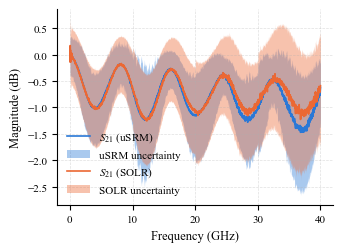

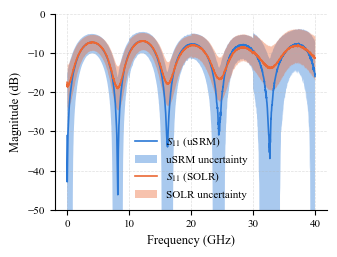

In [77]:
# +/-1 sigma uncertainty bands against the independent METAS SOLR reference.

DUT1,unc = calSRM.u_apply_cal(step_imp)

#DUT2,unc_2 = calSRM.u_apply_cal_unc(mismatch_p1,unc_mismatch_p1)
ref_solr  = rf.NetworkSet.from_dir("SOLR_Folder")
# mean_s_re/mean_s_im/std_s_re/std_s_im return Network objects; the actual

ref_solr_db = ref_solr.mean_s_db.s

ref_solr_std_db = ref_solr.std_s_db.s

freq_ghz = freq.f / 1e9

fig, ax = plt.subplots()
s21 = np.abs(DUT1.to_dataframe('s')['s 21'])
u21 = np.abs(unc[:,1,0])
ax.plot(freq_ghz, 20*np.log10(s21), color=COLOR_USRM, label='$S_{21}$ (uSRM)')
ax.fill_between(freq_ghz, 20*np.log10(s21-u21), 20*np.log10(s21+u21), color=COLOR_USRM, alpha=0.4, linewidth=0, label='uSRM uncertainty')
ax.plot(freq_ghz, ref_solr_db[:,1,0], color=COLOR_REF, label='$S_{21}$ (SOLR)')
ax.fill_between(freq_ghz,ref_solr_db[:,1,0]-ref_solr_std_db[:,1,0], ref_solr_db[:,1,0]+ref_solr_std_db[:,1,0], color=COLOR_REF, alpha=0.4, linewidth=0, label='SOLR uncertainty')
style_axes(ax, "Frequency (GHz)", "Magnitude (dB)")
savefig(fig, "Step_imp_S21.svg")

fig, ax = plt.subplots()
s11 = np.abs(DUT1.to_dataframe('s')['s 11'])
u11 = np.abs(unc[:,0,0])
ax.plot(freq_ghz, 20*np.log10(s11), color=COLOR_USRM, label='$S_{11}$ (uSRM)')
lower_bound_srm = np.where(s11-u11 <= 0, 1e-9, s11-u11)
ax.fill_between(freq_ghz, 20*np.log10(lower_bound_srm), 20*np.log10(s11+u11), color=COLOR_USRM, alpha=0.4, linewidth=0, label='uSRM uncertainty')
ax.plot(freq_ghz, ref_solr_db[:,0,0], color=COLOR_REF, label='$S_{11}$ (SOLR)')
ax.fill_between(freq_ghz,ref_solr_db[:,0,0]-ref_solr_std_db[:,0,0], ref_solr_db[:,0,0]+ref_solr_std_db[:,0,0], color=COLOR_REF, alpha=0.4, linewidth=0, label='SOLR uncertainty')
style_axes(ax, "Frequency (GHz)", "Magnitude (dB)")
ax.set_ylim(top=0,bottom=-50)
savefig(fig, "Step_imp_S11.svg")

plt.show()